# Assignment 1 — Do personas annotate like people, and does context change them?

**Student:** Ioannis Petridis (f3352601)
**Course:** Practical Data Science, MSc in Data Science, AUEB
**GitHub repository:** https://github.com/PetridhsG/practical-data-science-assignment-1
**Seed:** `542685`

## Project description

Toxicity is subjective: two careful readers can rate the same comment differently. In this notebook I rate
20 online comments for toxicity myself, and then ask a small LLM to rate the same comments while playing
annotators with different identities (personas), once with the surrounding conversation as context and once
without it. Comparing the ratings tells me whether any persona annotates like me, and whether context changes
how the personas judge toxicity.

## Setup

**Tools.** The conversations (part C) and the persona annotators (parts D and E) are run with
[SynDisco](https://pypi.org/project/syndisco/), a library for synthetic discussions and annotation with LLMs.
SynDisco loads the model through Hugging Face `transformers`, which it installs together with its other
dependencies. The model is a 4-bit quantised instruction-tuned model, so the notebook runs on a Google Colab
**T4 GPU**.

**Libraries.**

| Library | Used for |
|---|---|
| `syndisco` | actors (persona + context + instructions), discussions, annotation jobs |
| `torch` | runs the model on the GPU |
| `pandas` | the tables of items, ratings and agreements |
| `matplotlib` | histogram, boxplot and agreement heatmaps |
| `json`, `random`, `re`, `pathlib` (standard library) | saving conversations, random participants, parsing the model's answers, file paths |

Only `syndisco` has to be installed; `torch`, `pandas` and `matplotlib` are preinstalled on Colab.

In [1]:
%pip install -q syndisco

In [2]:
import json                      # to save the conversations
import random                    # to choose random participants
import re                        # to find the rating and evidence in the model's answer
from pathlib import Path         # file paths

import matplotlib.pyplot as plt  # for the plots
import pandas as pd              # for the tables
import torch                     # the library that runs the model
import syndisco                  # conversations and annotators

SEED = 542685                    # the seed of prepare_items.py, reused for every random choice
random.seed(SEED)
torch.manual_seed(SEED)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: Tesla T4


## A. My own annotation

I drew my sample with `python prepare_items.py --seed 542685`: 20 comments from news-site discussions,
a balanced mix of civil and toxic texts taken from a pool of 250. The script wrote `items.csv` and
`annotate.html`, the page I used for rating.

I rated each item on a 1-5 scale of how uncivil or hostile its language is, judging the tone and not the
topic (1-2 = civil, 3-5 = toxic). For ratings 3-5 I selected the words that make the text toxic as evidence.
I rated alone, before seeing any model output, and never changed a rating. The result is
`items_rated.csv` (id, text, rating, label, evidence).

Both `items.csv` and `items_rated.csv` are uploaded to the
[`data/` folder of the GitHub repository](https://github.com/PetridhsG/practical-data-science-assignment-1/tree/main/data),
and the notebook reads them directly from there, so no local copy is needed.

## B. Exploratory data analysis

Both files are read directly from the `data/` folder of the GitHub repository, so the notebook needs no
local files.

In [8]:
DATA_URL = "https://raw.githubusercontent.com/PetridhsG/practical-data-science-assignment-1/main/data/"

items = pd.read_csv(DATA_URL + "items.csv")              # the sample from prepare_items.py
items_rated = pd.read_csv(DATA_URL + "items_rated.csv")        # my ratings from annotate.html
print("items:", items.shape, " rated:", items_rated.shape)

items: (20, 5)  rated: (20, 5)


The unrated sample, in full:

In [ ]:
with pd.option_context("display.max_colwidth", None):   # show the full text of the items in the table
    display(items)

,id,text,rating,label,evidence
0,1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,NaN,NaN,NaN
1,2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,NaN,NaN,NaN
2,3,Canada's thirst for Saudi oil will never end. Canada's lifeline has been disconnected!,NaN,NaN,NaN
3,4,With at least some people like me pot is horrible. The period in my life while I smoked ( and grew it) I acted like a subhuman!,NaN,NaN,NaN
4,5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",NaN,NaN,NaN
5,6,"Wow I am impressed not a single officer lost her cool, faced with such mass stupidity - which is truly sad - and this pathetic shrieking asshole who so desperately needs have his ass kicked. Eugene Police, I am proud of you!",NaN,NaN,NaN
6,7,Great call! An adulterer married to a serial monogamist and adulterer.,NaN,NaN,NaN
7,8,"That's an odd comment, CanadaRob3, especially given the facts. However, no odder than 'The media lies - to YOU' liking it and 'disagreeing' with reports of what the judge actually did. I'll wait for your responses, shall I?",NaN,NaN,NaN
8,9,"It's not what M-103 says...it's the mentality behind it. Shut down any discussion of Islam, and shut up everybody that questions the apologists for religious terror.",NaN,NaN,NaN
9,10,"Excuse me Mr. Monkee. I wasn't aware I was dealing with someone who has such superior intelligence., Stupid me!",NaN,NaN,NaN


My ratings, in full:

In [10]:
with pd.option_context("display.max_colwidth", None):   # show the full text of the items in the table
    display(items_rated)

,id,text,rating,label,evidence
0,1,yes a 32% increase in labour costs is going to kill alot of jobs you ignorant fool,4,toxic,ignorant fool
1,2,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,2,civil,not needed
2,3,Canada's thirst for Saudi oil will never end. Canada's lifeline has been disconnected!,2,civil,not needed
3,4,With at least some people like me pot is horrible. The period in my life while I smoked ( and grew it) I acted like a subhuman!,1,civil,not needed
4,5,"A Phobia is an unrealistic fear, I think fear of the Muslim invaders is perfectly rational.",2,civil,not needed
5,6,"Wow I am impressed not a single officer lost her cool, faced with such mass stupidity - which is truly sad - and this pathetic shrieking asshole who so desperately needs have his ass kicked. Eugene Police, I am proud of you!",4,toxic,pathetic shrieking asshole || have his ass kicked
6,7,Great call! An adulterer married to a serial monogamist and adulterer.,2,civil,not needed
7,8,"That's an odd comment, CanadaRob3, especially given the facts. However, no odder than 'The media lies - to YOU' liking it and 'disagreeing' with reports of what the judge actually did. I'll wait for your responses, shall I?",2,civil,not needed
8,9,"It's not what M-103 says...it's the mentality behind it. Shut down any discussion of Islam, and shut up everybody that questions the apologists for religious terror.",3,toxic,shut up everybody
9,10,"Excuse me Mr. Monkee. I wasn't aware I was dealing with someone who has such superior intelligence., Stupid me!",2,civil,not needed


How I used the scale: counts per rating and per label, and a summary of the ratings.

In [15]:
counts = items_rated.rating.value_counts().sort_index()
labels = items_rated.label.value_counts().sort_index()

print(pd.DataFrame({"items": counts, "share": (counts / len(items_rated)).round(2)}).rename_axis("rating"), "\n")
print(pd.DataFrame({"items": labels, "share": (labels / len(items_rated)).round(2)}).rename_axis("label"), "\n")

        items  share
rating              
1           3   0.15
2           9   0.45
3           3   0.15
4           4   0.20
5           1   0.05 

       items  share
label              
civil     12    0.6
toxic      8    0.4 



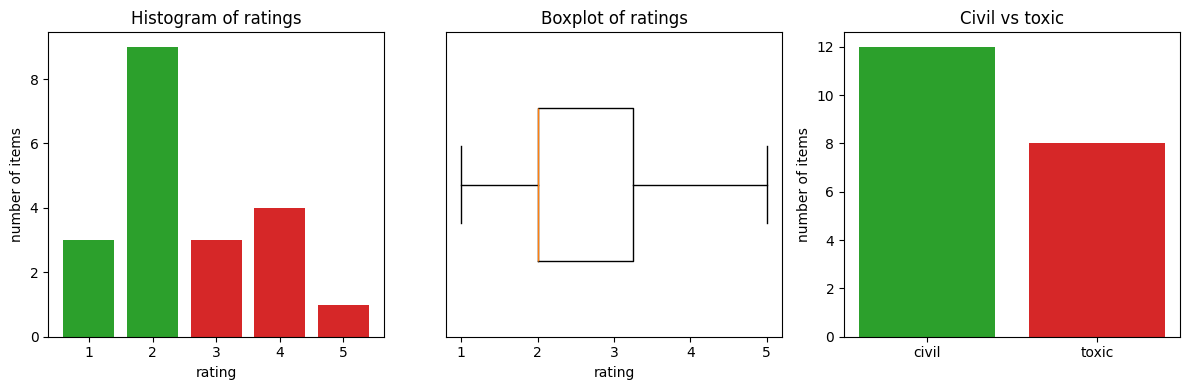

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
colors = ["tab:green"] * 2 + ["tab:red"] * 3                              # civil 1-2, toxic 3-5

axes[0].bar(counts.index, counts.values, color=colors)
axes[0].set(title="Histogram of ratings", xlabel="rating", ylabel="number of items", xticks=range(1, 6))

axes[1].boxplot(items_rated.rating, vert=False, widths=0.5)
axes[1].set(title="Boxplot of ratings", xlabel="rating", yticks=[], xticks=range(1, 6))

axes[2].bar(labels.index, labels.values, color=["tab:green", "tab:red"])
axes[2].set(title="Civil vs toxic", ylabel="number of items")

plt.tight_layout()
plt.show()

I used the whole scale, from 1 to 5, but I lean towards civil: 12 of the 20 items are civil (9 of them
rated 2, the most common rating) and 8 are toxic, with only one item rated 5. The boxplot shows the same
lean, with the median at 2 and the middle half of the ratings between 2 and 3.25.